# Tarea 1 - Métodos de Fourier
Trabajo realizado por Miguel Olivos, Miguel Piedrahita y Pablo Pulgarín

# Librerías necesarias

In [138]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
sp.init_printing(use_latex='mathjax') #Para la mejor visualización de los prints

# Determinación de coeficiente a<sub>nm</sub>

Primero definiremos los símbolos con los que trabajaremos. x,y, L, K son valores contínuos. n,m serán los contadores de nuestras sumatorias, por lo que son números enteros positivos

In [139]:
x,y, L, K = sp.symbols('x y L K', positive=True)
n,m = sp.symbols('n m', positive=True, integer=True)
L_val, K_val = 1.0, 1.0 #Dimensiones de la membrana
N_terms, M_terms = 20, 20 #Nos recomendaron utilizar entre 15 y 20

Después, definiremos la función con la que se trabajará como condición inicial. Se tienen 3 ejemplos extraídos del anexo.pdf

In [140]:
f_sym = x * (L - x) * y * (K - y)
nombre_funcion = 'funcion1'
#f_sym = x**2 * sp.sin(y)
#nombre_funcion = 'funcion2'
# f_sym = sp.sin(x)*sp.cos(y)
# nombre_funcion = 'funcion3'
f_sym

x⋅y⋅(K - y)⋅(L - x)

Esta función la utilizaremos para escribir toda la estructura para a<sub>nm</sub> descrita en el anexo. Imprimimos nuestro resultado

In [141]:
integrand = f_sym*sp.sin(n*sp.pi*x/L)*sp.sin(m*sp.pi*y/K)
integral = sp.integrate(integrand, (y,0,K), (x,0,L))
coef = sp.simplify((4 / (L*K)) * integral)
coef = sp.simplify(coef.subs({L: L_val, K: K_val})) #Fijaremos los valores de L y K = 1 para que no colapse. Sin embargo, las dimensiones de la membrana pueden cambiar según el problema
coef

     ⎛      m       n       m + n    ⎞
16.0⋅⎝- (-1)  - (-1)  + (-1)      + 1⎠
──────────────────────────────────────
                6  3  3               
               π ⋅m ⋅n                

Convertimos esta función simbólica a una función vectorial de numpy. Esto nos permitirá trabajar con cálculo vectorial en numpy

In [142]:
a_nm_func = sp.lambdify((n, m), coef, 'numpy')

Crearemos nuestros vectores fila (n) y columna (m) sobre los que se evaluará posteriormente la expresión para a<sub></sub>

In [143]:
n_vec = np.arange(1, N_terms + 1)[:, None] # Fila
m_vec = np.arange(1, M_terms + 1)[None, :] # Columna

Una vez realizado esto, simplemente evaluaremos nuestra función matricial y la guardaremos en la carpeta de coeficientes

In [144]:
a_nm = a_nm_func(n_vec, m_vec).astype(np.float64) # Convertimos a float64 para evitar problemas 
nombre_archivo = f"{'coeficientes/'}{nombre_funcion}{'_a_nm.npy'}"
np.save(nombre_archivo, a_nm)
print(f'Matriz a_nm generada. Forma: {a_nm.shape}')

Matriz a_nm generada. Forma: (20, 20)


## Vectorizacion y Calculo de la solucion de la membrana elastica 

Definimos un valor para la variable numerica a de la solucion que esta relacionada a la velocidad de propagacion.

In [145]:
a = 1

Definimos las mallas correspondientes a las posiciones espaciales de x, y y al tiempo. Estas permiten evaluar la funcion de desplazamiento en diferentes puntos y momentos de la membrana.

In [146]:
x = np.linspace(0, L_val, 30)
y = np.linspace(0, K_val, 30)
t = np.linspace(0, 5, 50) 
T,X,Y = np.meshgrid(t,x,y, indexing='ij')


Se construye una funcion que recibe la matriz de coeficientes a_nm, las dimenciones de la membrana los indices de la sumatoria, la velocidad de propagacion y las mayas definidas en el paso anterior, se utiliza el mecanismo de broadcasting para operar las matrices de diferentes dimensiones

In [147]:
def Calcular_sln(a_nm, L, K, a, X, Y, T):

    n = np.arange(1, a_nm.shape[0] + 1)
    m = np.arange(1, a_nm.shape[1] + 1)

    A = a_nm[:, :, None, None, None]
    N = n[:, None, None, None, None]
    M = m[None, :, None, None, None]
    X = X[None, None, :, :, :]
    Y = Y[None, None, :, :, :]
    T = T[None, None, :, :, :]

    terminos = A*np.sin(N*np.pi*X/L)*np.sin(M*np.pi*Y/K)*np.cos(np.pi*a*T*np.sqrt((N/L)**2 + (M/K)**2))
    Sumatoria = np.sum(terminos, axis=(0, 1))
    return Sumatoria

Se cargan los archivos que contienen los coeficientes de fourier correspondientes a cada una de las funciones.

In [148]:
a_nm_1 = np.load('coeficientes/funcion1_a_nm.npy', allow_pickle=True)
a_nm_2 = np.load('coeficientes/funcion2_a_nm.npy', allow_pickle=True)
a_nm_3 = np.load('coeficientes/funcion3_a_nm.npy', allow_pickle=True)
print(a_nm_1.dtype, a_nm_2.dtype, a_nm_3.dtype)

float64 float64 float64


Se utiliza la función definida anterior mente para calcular la solucion de la membrana en cada uno de los casos.

In [149]:
Z1 = Calcular_sln(a_nm_1, L_val, K_val, a, X, Y, T)
Z2 = Calcular_sln(a_nm_2, L_val, K_val, a, X, Y, T)
Z3 = Calcular_sln(a_nm_3, L_val, K_val, a, X, Y, T)

Para evitar repetir los cálculos, se almacenan las soluciones obtenidas en archivos .npy, que podrán cargarse posteriormente para realizar las animaciones.

In [150]:
np.save('soluciones/z_funcion1.npy', Z1)
np.save('soluciones/z_funcion2.npy', Z2)
np.save('soluciones/z_funcion3.npy', Z3)

Visualización y Animación de la Membrana

Animación 3D de la Membrana Elástica

In [151]:
from IPython.display import Image, display 
#Basiccamente esto se usa como un puente para mostrar imágenes en el notebook.
#No es necesario para la animación, pero es útil para mostrar imágenes estáticas.

Seleccionar funcion y ajustar la figura.

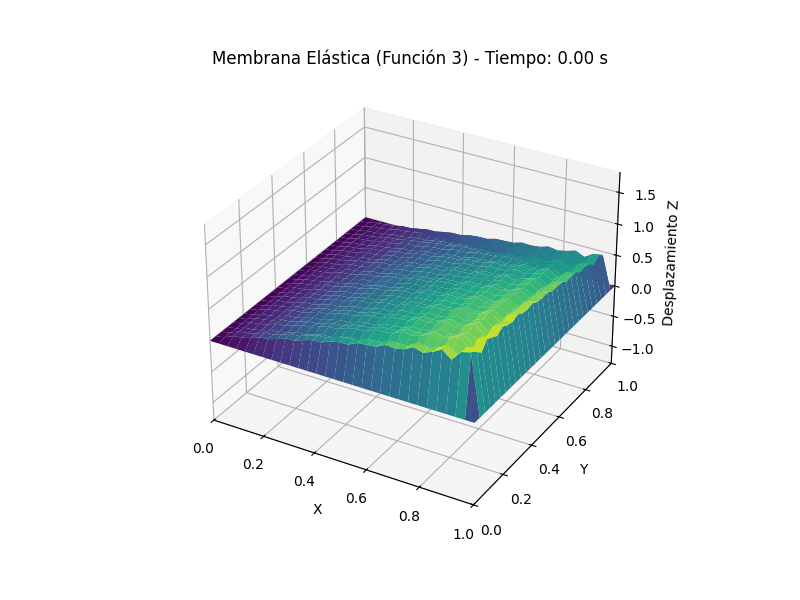

In [152]:
# Seleccionar qué función animar (1, 2 o 3)
opcion = int(input("ingrese el número de la función que desea animar (1, 2 o 3): "))
Z = np.load(f'soluciones/z_funcion{opcion}.npy')


fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

z_min, z_max = Z.min(), Z.max()

# 3. Función de actualización para cada cuadro
def update(frame):
    ax.clear()
    
    # Extraer las mallas 2D
    X_frame = X[frame, :, :]
    Y_frame = Y[frame, :, :]
    Z_frame = Z[frame, :, :]
    # Dibujar la superficie 3D de la membrana
    superf = ax.plot_surface(X_frame, Y_frame, Z_frame, cmap='viridis', edgecolor='none')
    
    # límites y títulos
    ax.set_xlim(0, L_val)
    ax.set_ylim(0, K_val)
    ax.set_zlim(z_min, z_max)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Desplazamiento Z')
    ax.set_title(f"Membrana Elástica (Función {opcion}) - Tiempo: {t[frame]:.2f} s")
    
    return superf,

# 4. Generar la animación
anim = animation.FuncAnimation(fig, update, frames=len(t), interval=50, blit=False)

# 5. Guardar como GIF en la carpeta 'soluciones'
ruta_gif = f'soluciones/membrana_funcion{opcion}.gif'
anim.save(ruta_gif, writer='pillow', fps=20)
plt.close(fig)  # Oculta el lienzo estático vacíoe

# 6. Mostrar el GIF animado directamente en la celda
display(Image(filename=ruta_gif))